In [2]:
import torch
import torch.nn as nn
import torchvision.models as models
import torchvision.transforms as transforms
from PIL import Image, ImageDraw, ImageFont
import matplotlib.pyplot as plt

In [3]:
!pip install captum shap lime scikit-image grad-cam --quiet

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 10.7 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.5/44.5 kB 3.7 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 455.2/455.2 kB 26.0 MB/s eta 0:00:00


In [4]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import requests
from io import BytesIO


In [5]:
from captum.attr import IntegratedGradients, Occlusion, GuidedBackprop

In [6]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device

device(type='cuda')

In [7]:
from torchvision.models import resnet50, ResNet50_Weights

weights = ResNet50_Weights.DEFAULT
model = resnet50(weights=weights)

model = model.eval().to(device)

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 200MB/s]


In [8]:
preprocess = weights.transforms()

imagenet_labels = weights.meta["categories"]

In [9]:
IMAGE_URL = "https://images.pexels.com/photos/417074/pexels-photo-417074.jpeg"

In [10]:
response = requests.get(IMAGE_URL)

img_pil = Image.open(BytesIO(response.content)).convert("RGB")

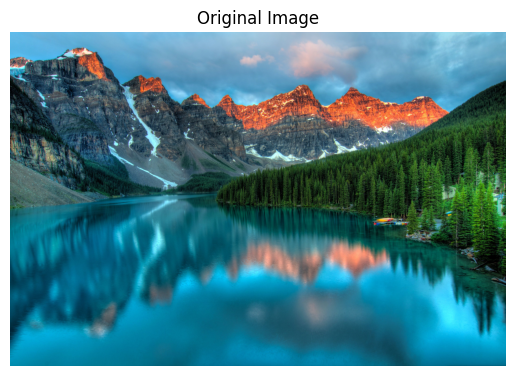

In [11]:
plt.imshow(img_pil)
plt.axis("off")
plt.title("Original Image")
plt.show()

In [12]:
def prepare_image(img_pil):
    # preprocess returns a tensor [C,H,W], we need [1,C,H,W]
    input_tensor = preprocess(img_pil).unsqueeze(0).to(device)
    return input_tensor

In [13]:
def predict(input_tensor):
    with torch.no_grad():
        logits = model(input_tensor)

    probs = logits.softmax(dim=1)
    return probs, logits

In [14]:
input_tensor = prepare_image(img_pil)

probs, logits = predict(input_tensor)

In [15]:
top_prob, top_idx = probs.max(dim=1)

pred_label = imagenet_labels[top_idx.item()]

print(f"Top prediction: {pred_label} (prob={top_prob.item():.3f})")

Top prediction: valley (prob=0.271)


In [16]:
occlusion = Occlusion(model)

input_tensor.requires_grad = False

target = top_idx.item()

In [17]:
attributions_occ = occlusion.attribute(
    input_tensor,
    strides=(1, 8, 8),
    target=target,
    sliding_window_shapes=(1, 15, 15),
    baselines=0
)

In [18]:
attr_occ = attributions_occ.squeeze().detach().cpu().numpy()
attr_occ = attr_occ.sum(axis=0)

In [19]:
attr_occ_norm = (attr_occ - attr_occ.min()) / (
    attr_occ.max() - attr_occ.min() + 1e-8
)

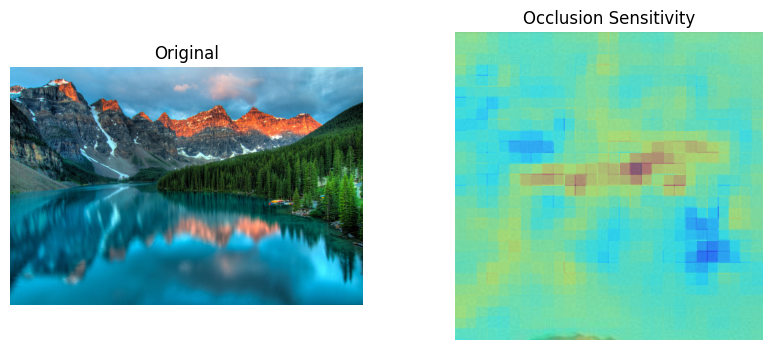

In [20]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(img_pil)
plt.title("Original")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(img_pil)
plt.imshow(attr_occ_norm, cmap="jet", alpha=0.5)
plt.title("Occlusion Sensitivity")
plt.axis("off")

plt.show()

In [21]:
ig = IntegratedGradients(model)

baseline = torch.zeros_like(input_tensor).to(device)

In [22]:
attributions_ig = ig.attribute(
    input_tensor,
    baselines=baseline,
    target=target,
    n_steps=50
)

In [23]:
attr_ig = attributions_ig.squeeze().detach().cpu().numpy()

attr_ig = attr_ig.sum(axis=0)

In [24]:
attr_ig_norm = (attr_ig - attr_ig.min()) / (
    attr_ig.max() - attr_ig.min() + 1e-8
)

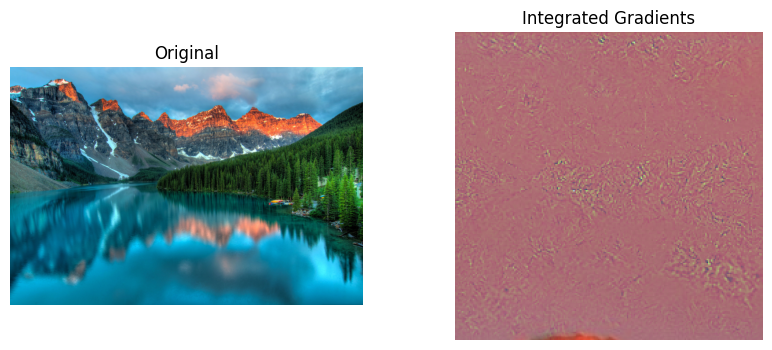

In [25]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(img_pil)
plt.title("Original")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(img_pil)
plt.imshow(attr_ig_norm, cmap="hot", alpha=0.5)
plt.title("Integrated Gradients")
plt.axis("off")

plt.show()

In [26]:
gbp = GuidedBackprop(model)

input_tensor.requires_grad = True

In [27]:
attributions_gbp = gbp.attribute(input_tensor, target=target)

/usr/local/lib/python3.13/dist-packages/captum/attr/_core/guided_backprop_deconvnet.py:66: UserWarning: Setting backward hooks on ReLU activations.The hooks will be removed after the attribution is finished
  warnings.warn(


In [28]:
attr_gbp = attributions_gbp.squeeze().detach().cpu().numpy()

attr_gbp = np.abs(attr_gbp).sum(axis=0)

In [29]:
attr_gbp_norm = (attr_gbp - attr_gbp.min()) / (
    attr_gbp.max() - attr_gbp.min() + 1e-8
)

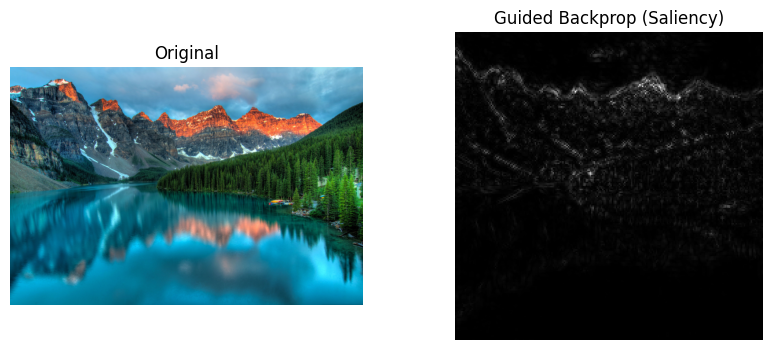

In [30]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(img_pil)
plt.title("Original")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(attr_gbp_norm, cmap="gray")
plt.title("Guided Backprop (Saliency)")
plt.axis("off")

plt.show()

In [31]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from torchvision.utils import make_grid
import matplotlib.pyplot as plt

In [32]:
from lime import lime_image
from skimage.segmentation import mark_boundaries

In [33]:
import shap

In [34]:
from pytorch_grad_cam import GradCAM, GradCAMPlusPlus
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

In [35]:
!pip install shap lime scikit-image grad-cam --quiet

In [36]:
input_tensor = preprocess(img_pil).unsqueeze(0).to(device)

In [37]:
model.eval()

with torch.no_grad():
    logits = model(input_tensor)
    probs = logits.softmax(dim=1)

top_prob, top_idx = probs.max(dim=1)

In [38]:
target = top_idx.item()
pred_label = imagenet_labels[target]

print(f"Top prediction: {pred_label} (class id={target}, prob={top_prob.item():.3f})")

Top prediction: valley (class id=979, prob=0.271)


In [39]:
target_layers = [model.layer4[-1]]

In [40]:
cam = GradCAM(
    model=model,
    target_layers=target_layers
)

In [41]:
targets = [ClassifierOutputTarget(target)]

In [42]:
grayscale_cam = cam(input_tensor=input_tensor, targets=targets)[0]

In [43]:
H_cam, W_cam = grayscale_cam.shape
img_resized = img_pil.resize((W_cam, H_cam))

rgb_img = np.array(img_resized).astype(np.float32) / 255.0

In [44]:
visualization = show_cam_on_image(
    rgb_img,
    grayscale_cam,
    use_rgb=True
)

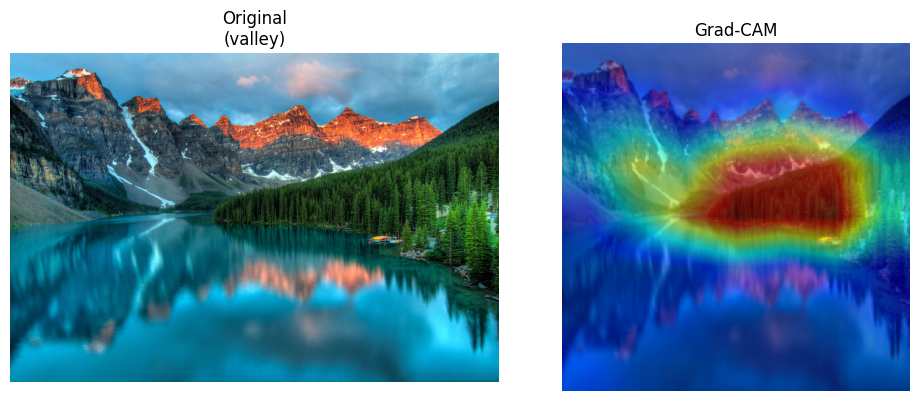

In [45]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(img_pil)
plt.title(f"Original\n({pred_label})")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(visualization)
plt.title("Grad-CAM")
plt.axis("off")

plt.tight_layout()
plt.show()

In [46]:
target_layers = [model.layer4[-1]]

cam_pp = GradCAMPlusPlus(
    model=model,
    target_layers=target_layers
)

In [47]:
targets = [ClassifierOutputTarget(target)]

In [48]:
grayscale_cam_pp = cam_pp(
    input_tensor=input_tensor,
    targets=targets
)[0]

In [49]:
H_cam, W_cam = grayscale_cam_pp.shape

img_resized_pp = img_pil.resize((W_cam, H_cam))

rgb_img_pp = np.array(img_resized_pp).astype(
    np.float32
) / 255.0

In [50]:
visualization_pp = show_cam_on_image(
    rgb_img_pp,
    grayscale_cam_pp,
    use_rgb=True
)

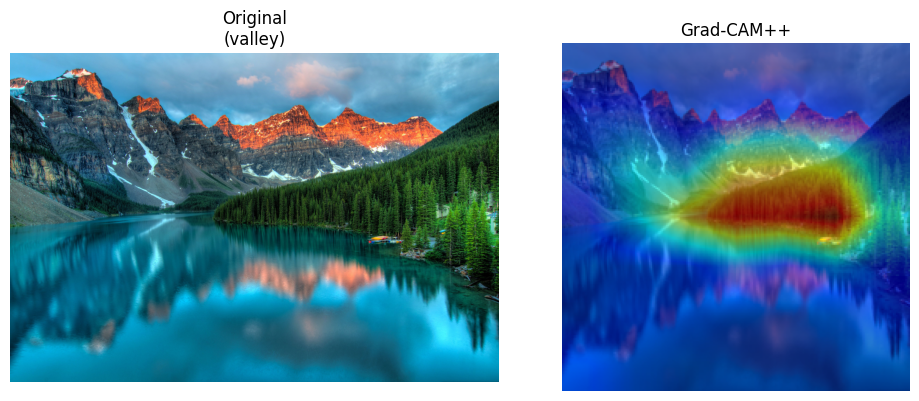

In [51]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(img_pil)
plt.title(f"Original\n({pred_label})")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(visualization_pp)
plt.title("Grad-CAM++")
plt.axis("off")

plt.tight_layout()
plt.show()

In [52]:
from lime import lime_image
from skimage.segmentation import mark_boundaries
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

In [55]:
def batch_predict(images):
    """
    images: list/array of images as float32 in [0,1], shape (H,W,3)
    returns: numpy array of probabilities [N, num_classes]
    """
    model.eval()
    batch_tensors = []

    for img in images:
        # img is HWC, float [0,1] → uint8 → PIL
        pil = Image.fromarray((img * 255).astype(np.uint8))
        t = preprocess(pil)
        batch_tensors.append(t)

    batch = torch.stack(batch_tensors).to(device)

    with torch.no_grad():
        logits = model(batch)
        probs = logits.softmax(dim=1)

    return probs.cpu().numpy()

In [57]:


img_lime = np.array(img_pil).astype(np.float32) / 255.0

print("Image prepared for LIME")
print("Image shape:", img_lime.shape)

Image prepared for LIME
Image shape: (2847, 4226, 3)


In [58]:
Create LIME explainer

from lime import lime_image

explainer = lime_image.LimeImageExplainer()

print("LIME explainer created successfully")

LIME explainer created successfully


In [59]:
# Cell 55 - Generate LIME explanation

explanation = explainer.explain_instance(
    img_lime,
    batch_predict,
    top_labels=5,
    hide_color=0,
    num_samples=20
)

print("LIME explanation generated successfully")

  0%|          | 0/20 [00:00<?, ?it/s]

LIME explanation generated successfully


In [60]:


lime_label = target

print("Target class:", lime_label)
print("Predicted label:", pred_label)

Target class: 979
Predicted label: valley


In [62]:


temp, mask = explanation.get_image_and_mask(
    lime_label,
    positive_only=True,
    num_features=5,
    hide_rest=False
)

print("Important image regions identified")

Important image regions identified


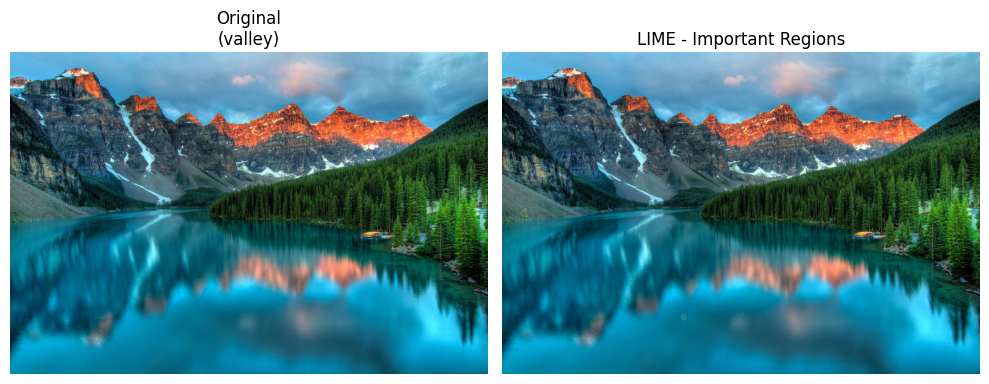

In [64]:


plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(img_pil)
plt.title(f"Original\n({pred_label})")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(mark_boundaries(temp, mask))
plt.title("LIME - Important Regions")
plt.axis("off")

plt.tight_layout()
plt.show()

In [65]:
import shap
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import torch
import torchvision.transforms as T

print("SHAP imported successfully")

SHAP imported successfully


In [66]:
model.eval()
model.to(device)

input_tensor = input_tensor.to(device)

print("Model and input tensor are ready")
print("Input shape:", input_tensor.shape)

Model and input tensor are ready
Input shape: torch.Size([1, 3, 224, 224])


In [78]:
background_images = []

bg_transform = T.Compose([
    T.RandomResizedCrop(size=img_pil.size[0], scale=(0.6, 1.0)),
    T.RandomHorizontalFlip()
])

for _ in range(20):
    bg_pil = bg_transform(img_pil)
    bg_tensor = preprocess(bg_pil)
    background_images.append(bg_tensor)

background = torch.stack(background_images).to(device)

print("Background created")
print("Background shape:", background.shape)

Background created
Background shape: torch.Size([20, 3, 224, 224])


In [85]:
import torchvision
import torch.nn as nn

# Disable in-place ReLU operations
for module in model.modules():
    if isinstance(module, nn.ReLU):
        module.inplace = False

# Replace ResNet Bottleneck forward pass
def safe_forward(self, x):
    identity = x

    out = self.conv1(x)
    out = self.bn1(out)
    out = self.relu(out)

    out = self.conv2(out)
    out = self.bn2(out)
    out = self.relu(out)

    out = self.conv3(out)
    out = self.bn3(out)

    if self.downsample is not None:
        identity = self.downsample(x)

    # Safe addition - NOT in-place
    out = out + identity

    out = self.relu(out)

    return out


# Apply the safe forward function
for module in model.modules():
    if isinstance(module, torchvision.models.resnet.Bottleneck):
        module.forward = safe_forward.__get__(
            module,
            module.__class__
        )

model.eval()

print("ResNet fixed successfully for SHAP")

ResNet fixed successfully for SHAP


In [86]:
import shap

explainer_shap = shap.GradientExplainer(
    model,
    background
)

print("SHAP GradientExplainer created successfully")

SHAP GradientExplainer created successfully


In [89]:


import shap

model.eval()

explainer_shap = shap.GradientExplainer(
    model,
    background
)

print("GradientExplainer created successfully")

GradientExplainer created successfully


In [5]:
import torch
import torch.nn as nn
import torchvision
import torchvision.models as models
import torchvision.transforms as transforms
from torchvision.models import resnet50, ResNet50_Weights

from PIL import Image
import matplotlib.pyplot as plt
import numpy as np
import requests
from io import BytesIO

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

Device: cuda


In [6]:
weights = ResNet50_Weights.DEFAULT

model = resnet50(weights=weights)

model = model.eval().to(device)

print("ResNet-50 loaded successfully")

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 124MB/s]


ResNet-50 loaded successfully


In [7]:
preprocess = weights.transforms()

imagenet_labels = weights.meta["categories"]

print("Preprocessing and ImageNet labels loaded")

Preprocessing and ImageNet labels loaded


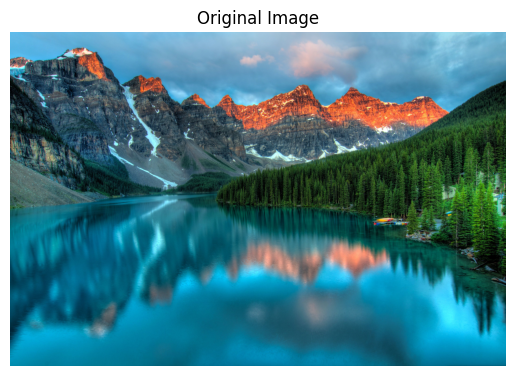

In [8]:
IMAGE_URL = "https://images.pexels.com/photos/417074/pexels-photo-417074.jpeg"

response = requests.get(IMAGE_URL)

img_pil = Image.open(
    BytesIO(response.content)
).convert("RGB")

plt.imshow(img_pil)
plt.axis("off")
plt.title("Original Image")
plt.show()

In [9]:
input_tensor = preprocess(
    img_pil
).unsqueeze(0).to(device)

with torch.no_grad():
    logits = model(input_tensor)
    probs = torch.softmax(logits, dim=1)

top_prob, top_idx = probs.max(dim=1)

target = top_idx.item()
pred_label = imagenet_labels[target]

print(
    f"Top prediction: {pred_label} "
    f"(prob={top_prob.item():.3f})"
)

Top prediction: valley (prob=0.271)


In [10]:
# Prepare image for explanation

image_np = np.array(
    img_pil
).astype(np.float32) / 255.0

model.eval()

original_tensor = preprocess(
    img_pil
).unsqueeze(0).to(device)

with torch.no_grad():
    original_output = model(original_tensor)
    original_probs = torch.softmax(
        original_output,
        dim=1
    )

target_class = original_probs.argmax(
    dim=1
).item()

original_score = original_probs[
    0,
    target_class
].item()

print("Predicted class:", pred_label)
print("Original probability:", original_score)

Predicted class: valley
Original probability: 0.2713499963283539


In [11]:
# Create feature-importance explanation

H, W, _ = image_np.shape

# Divide image into an 8 x 8 grid
grid_size = 8

importance_map = np.zeros((grid_size, grid_size))

for i in range(grid_size):
    for j in range(grid_size):

        # Make a copy of the original image
        modified_image = image_np.copy()

        # Calculate region coordinates
        y1 = int(i * H / grid_size)
        y2 = int((i + 1) * H / grid_size)

        x1 = int(j * W / grid_size)
        x2 = int((j + 1) * W / grid_size)

        # Hide this region
        modified_image[y1:y2, x1:x2] = 0

        # Convert NumPy image to PIL
        modified_pil = Image.fromarray(
            (modified_image * 255).astype(np.uint8)
        )

        # Preprocess image
        modified_tensor = preprocess(
            modified_pil
        ).unsqueeze(0).to(device)

        # Get model prediction
        with torch.no_grad():
            modified_output = model(modified_tensor)
            modified_probs = torch.softmax(
                modified_output,
                dim=1
            )

        # Probability after hiding this region
        modified_score = modified_probs[
            0,
            target_class
        ].item()

        # Importance = decrease in prediction
        importance_map[i, j] = (
            original_score - modified_score
        )

print("Feature-importance map created successfully")

Feature-importance map created successfully


In [12]:
# Resize feature-importance map to image size

importance_resized = np.array(
    Image.fromarray(
        importance_map.astype(np.float32)
    ).resize(
        (W, H)
    )
)

# Normalize values between 0 and 1

min_value = importance_resized.min()
max_value = importance_resized.max()

importance_normalized = (
    importance_resized - min_value
) / (
    max_value - min_value + 1e-8
)

print("Importance map resized and normalized")

Importance map resized and normalized


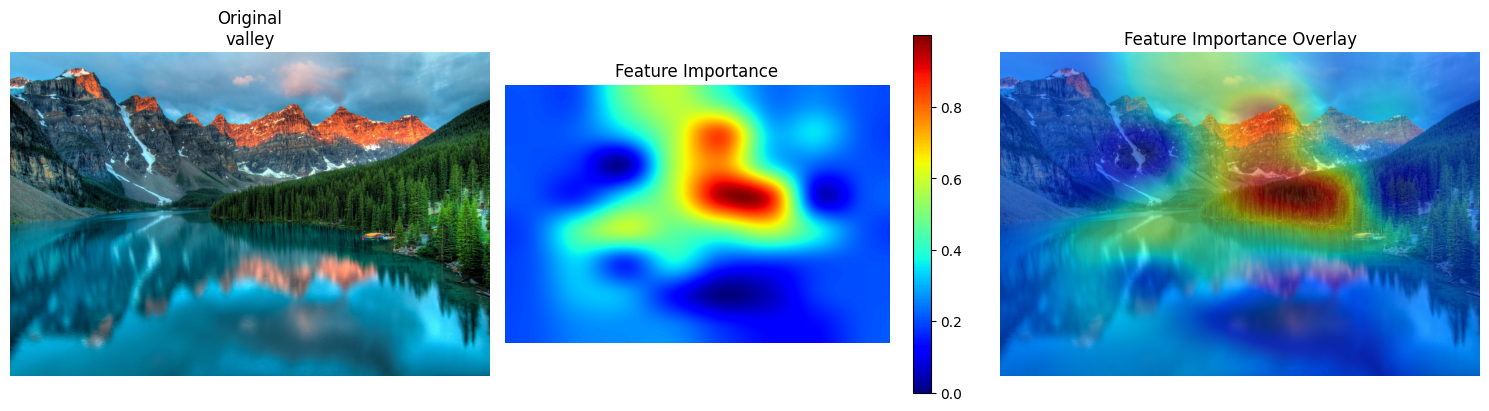

In [14]:


plt.figure(figsize=(15, 4))

plt.subplot(1, 3, 1)
plt.imshow(img_pil)
plt.title(f"Original\n{pred_label}")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(
    importance_normalized,
    cmap="jet"
)
plt.colorbar()
plt.title("Feature Importance")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(img_pil)
plt.imshow(
    importance_normalized,
    cmap="jet",
    alpha=0.5
)
plt.title("Feature Importance Overlay")
plt.axis("off")

plt.tight_layout()
plt.show()